In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [2]:
df = pd.read_csv('../data/heart_cleveland_upload.csv')

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [4]:
print("Rows and Columns:", df.shape)

Rows and Columns: (297, 14)


In [5]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.676768,0.468500,0.0,0.0,1.0,1.0,1.0
cp,297.0,2.158249,0.964859,0.0,2.0,2.0,3.0,3.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.144781,0.352474,0.0,0.0,0.0,0.0,1.0
restecg,297.0,0.996633,0.994914,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.326599,0.469761,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


In [8]:
df.isnull().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
condition    0
dtype: int64

In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


#Identifying Features

In [10]:
# Target Variable
target = 'condition'

# Predictor Variables
X = df.drop(columns=target)

# Target Variable
y = df[target]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (297, 13)
Target Shape : (297,)


In [11]:
numerical_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [12]:
print("Total Features :", len(X.columns))
print("Numerical Features :", len(numerical_features))
print("Categorical Features :", len(categorical_features))

Total Features : 13
Numerical Features : 5
Categorical Features : 8


In [13]:
df['condition'].value_counts()

condition
0    160
1    137
Name: count, dtype: int64

In [14]:
round(df['condition'].value_counts(normalize=True)*100,2)

condition
0    53.87
1    46.13
Name: proportion, dtype: float64

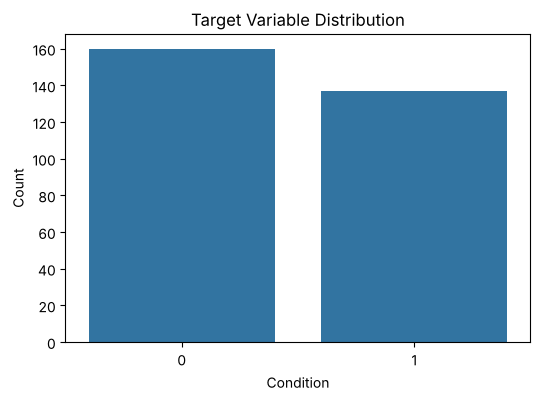

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(x='condition', data=df)

plt.title("Target Variable Distribution")
plt.xlabel("Condition")
plt.ylabel("Count")

plt.show()

**Reading the chart:** the target is fairly balanced — 160 patients without heart disease (53.9%) and 137 with it (46.1%) — so accuracy is a fair headline metric and no resampling is needed.

#Feature Understanding.

#Numerical Features

Feature 1

In [16]:
print(df['age'].describe())

count    297.000000
mean      54.542088
std        9.049736
min       29.000000
25%       48.000000
50%       56.000000
75%       61.000000
max       77.000000
Name: age, dtype: float64


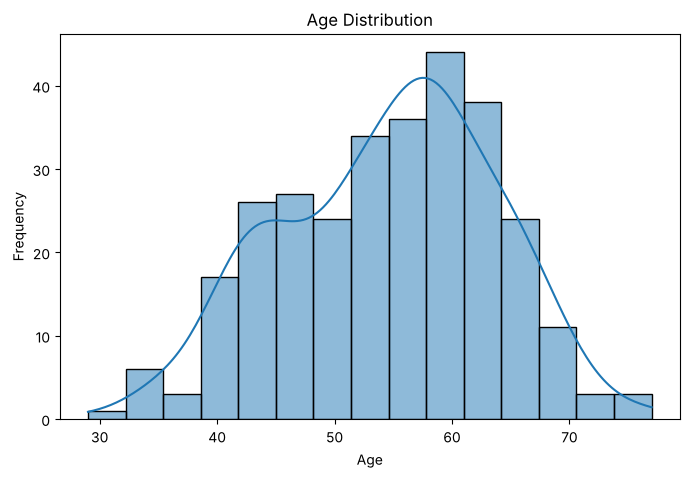

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=15, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

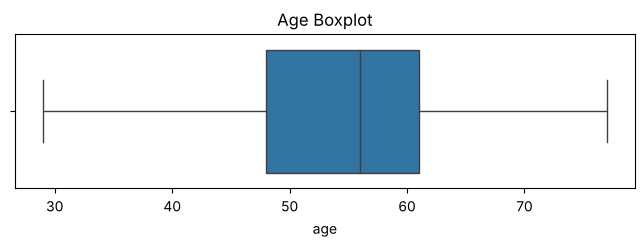

In [18]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['age'])

plt.title("Age Boxplot")

plt.show()

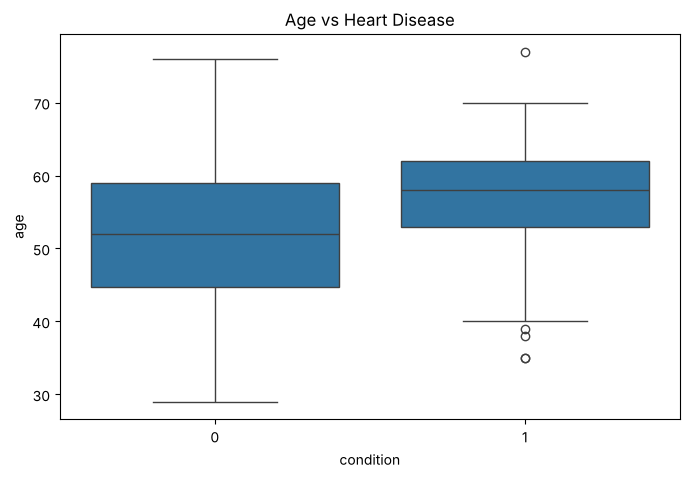

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='age', data=df)

plt.title("Age vs Heart Disease")

plt.show()

**Age:** patients with heart disease are older on average (median 58 vs 52 years). Age alone is a weak-to-moderate signal (correlation ≈ 0.23).

Feature 2

In [20]:
print(df['trestbps'].describe())

count    297.000000
mean     131.693603
std       17.762806
min       94.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64


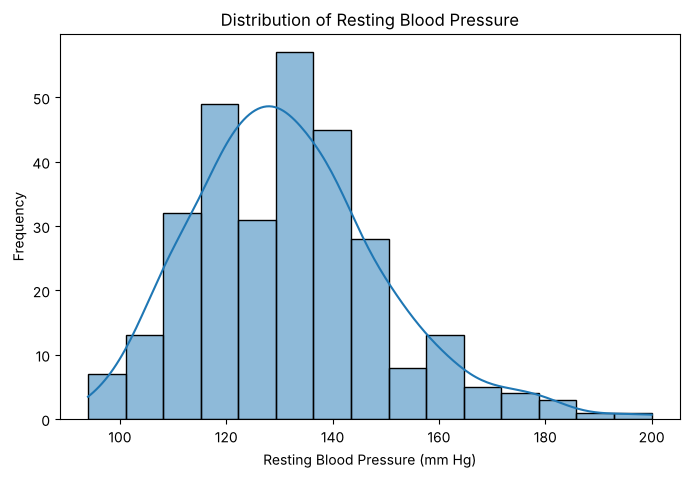

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(df['trestbps'], bins=15, kde=True)

plt.title("Distribution of Resting Blood Pressure")
plt.xlabel("Resting Blood Pressure (mm Hg)")
plt.ylabel("Frequency")

plt.show()

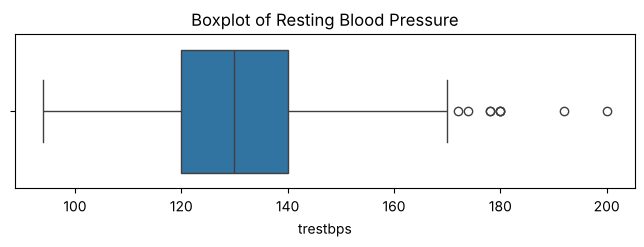

In [22]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['trestbps'])

plt.title("Boxplot of Resting Blood Pressure")

plt.show()

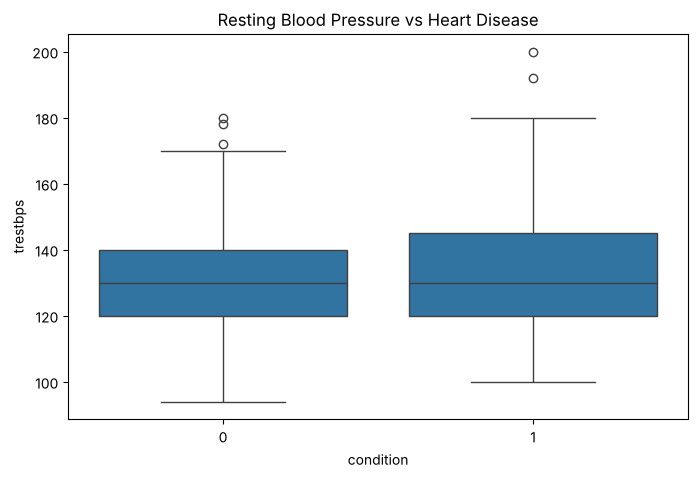

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='trestbps', data=df)

plt.title("Resting Blood Pressure vs Heart Disease")

plt.show()

**Resting blood pressure:** the two groups overlap heavily (median 130 mm Hg in both), so `trestbps` is only a weak predictor on its own.

Feature 3

In [24]:
print(df['chol'].describe())

count    297.000000
mean     247.350168
std       51.997583
min      126.000000
25%      211.000000
50%      243.000000
75%      276.000000
max      564.000000
Name: chol, dtype: float64


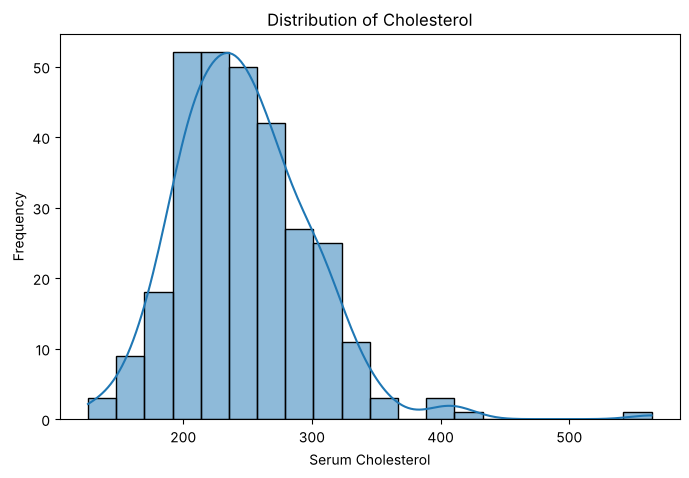

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(df['chol'], bins=20, kde=True)

plt.title("Distribution of Cholesterol")
plt.xlabel("Serum Cholesterol")
plt.ylabel("Frequency")

plt.show()

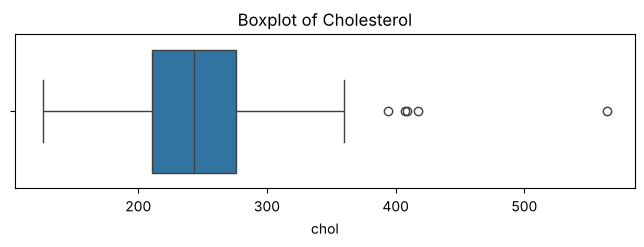

In [26]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['chol'])

plt.title("Boxplot of Cholesterol")

plt.show()

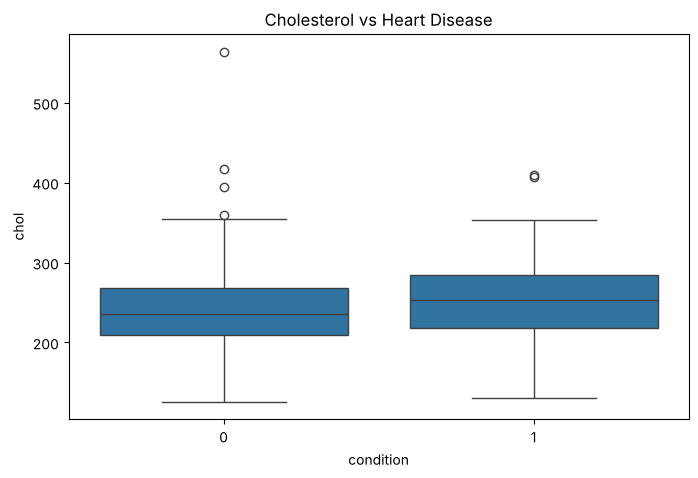

In [27]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='chol', data=df)

plt.title("Cholesterol vs Heart Disease")

plt.show()

**Cholesterol:** almost no separation between the groups (correlation ≈ 0.08) and a few extreme outliers (up to 564 mg/dl). Cholesterol is one of the least useful features here.

In [28]:
print(df['thalach'].describe())

count    297.000000
mean     149.599327
std       22.941562
min       71.000000
25%      133.000000
50%      153.000000
75%      166.000000
max      202.000000
Name: thalach, dtype: float64


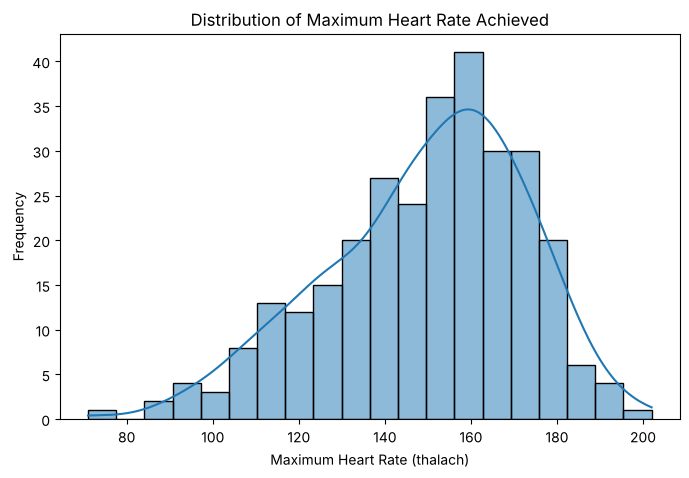

In [29]:
plt.figure(figsize=(8,5))

sns.histplot(df['thalach'], bins=20, kde=True)

plt.title('Distribution of Maximum Heart Rate Achieved')
plt.xlabel('Maximum Heart Rate (thalach)')
plt.ylabel('Frequency')

plt.show()

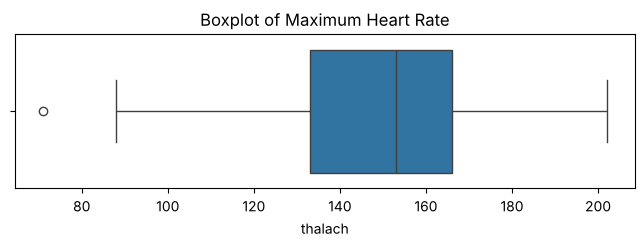

In [30]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['thalach'])

plt.title('Boxplot of Maximum Heart Rate')

plt.show()

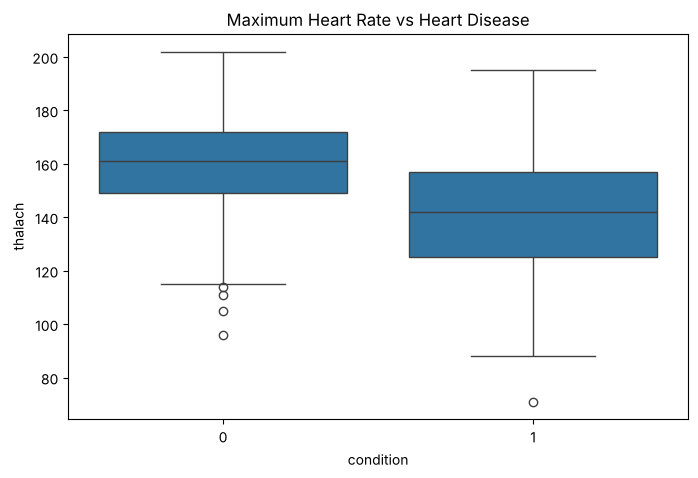

In [31]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='thalach', data=df)

plt.title('Maximum Heart Rate vs Heart Disease')

plt.show()

**Maximum heart rate:** patients with heart disease reach a clearly **lower** peak heart rate (median 142 vs 161 bpm) — the only feature that is negatively correlated with disease (≈ −0.42).

In [32]:
print(df['oldpeak'].describe())

count    297.000000
mean       1.055556
std        1.166123
min        0.000000
25%        0.000000
50%        0.800000
75%        1.600000
max        6.200000
Name: oldpeak, dtype: float64


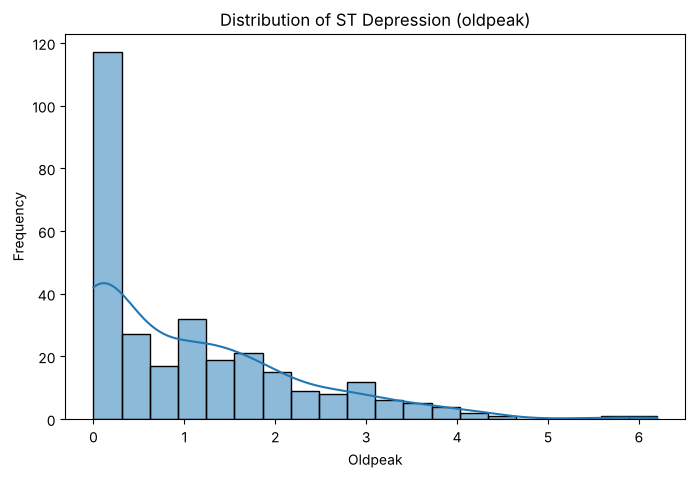

In [33]:
plt.figure(figsize=(8,5))

sns.histplot(df['oldpeak'], bins=20, kde=True)

plt.title("Distribution of ST Depression (oldpeak)")
plt.xlabel("Oldpeak")
plt.ylabel("Frequency")

plt.show()

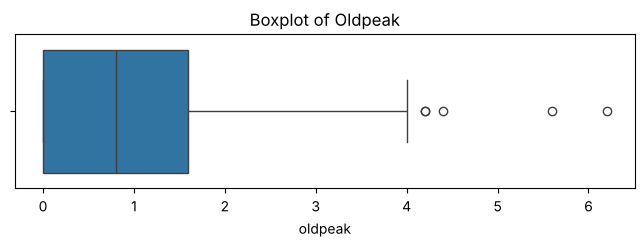

In [34]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['oldpeak'])

plt.title("Boxplot of Oldpeak")

plt.show()

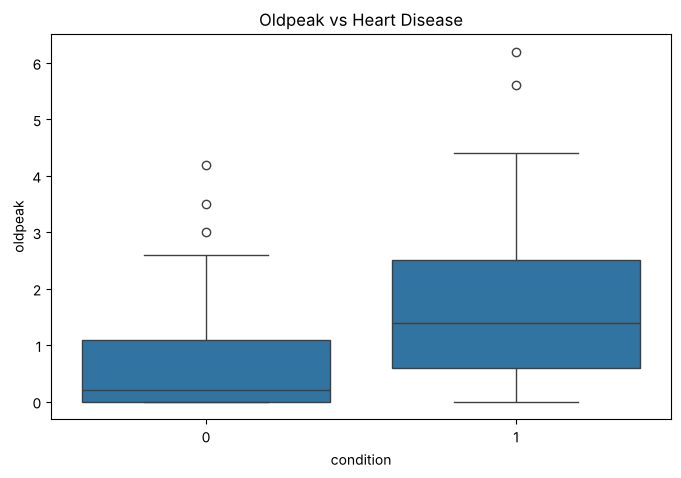

In [35]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='oldpeak', data=df)

plt.title("Oldpeak vs Heart Disease")

plt.show()

**ST depression (`oldpeak`):** healthy patients are concentrated near 0, while patients with disease have much higher values (median 1.4 vs 0.2). A strong predictor (correlation ≈ 0.42).

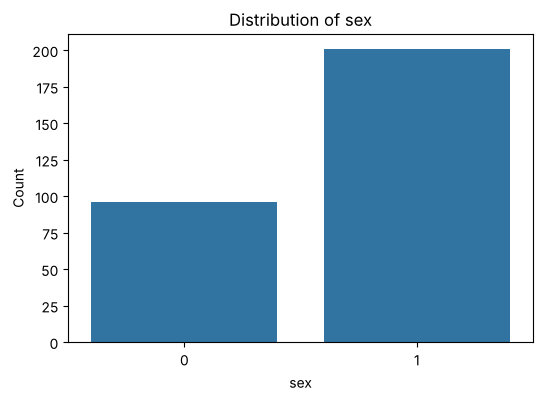

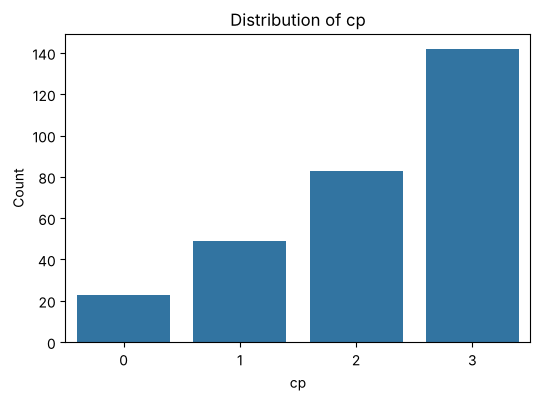

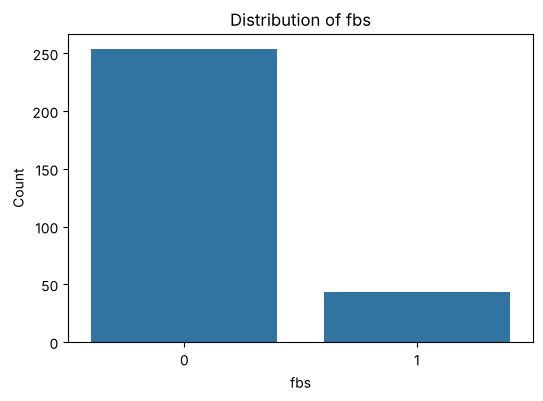

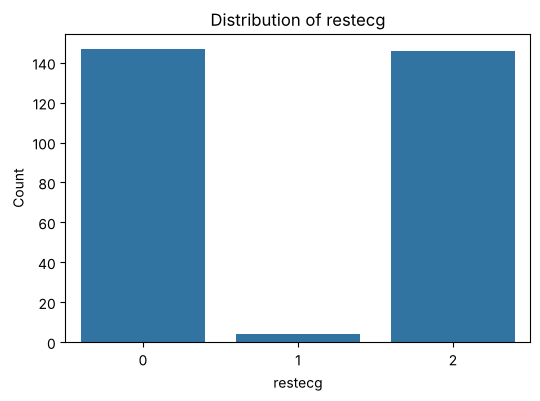

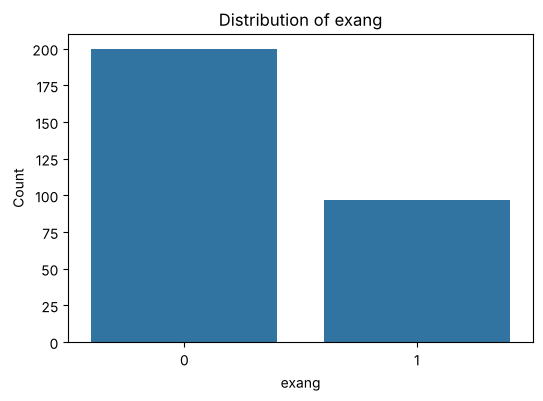

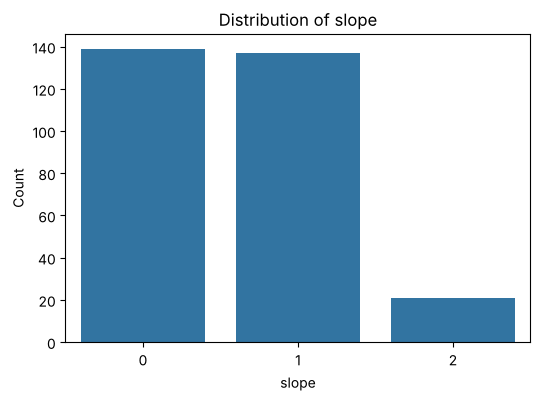

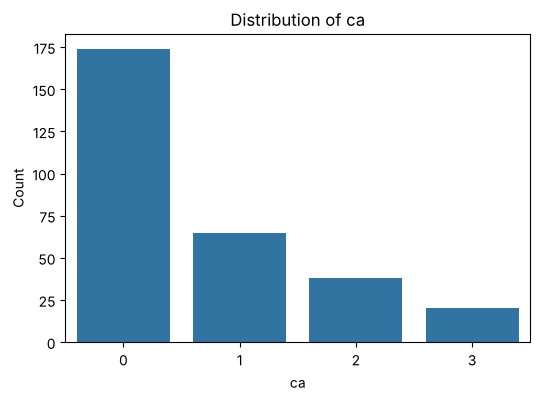

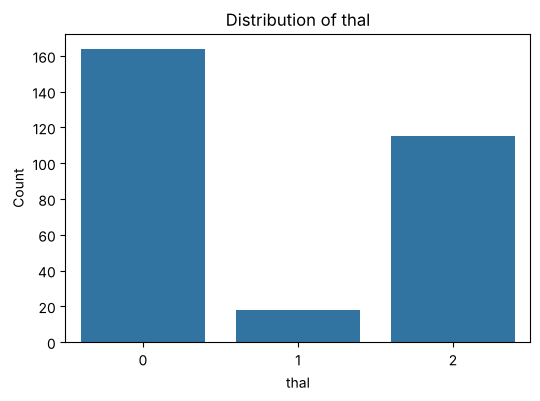

In [36]:
cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for col in cat_features:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

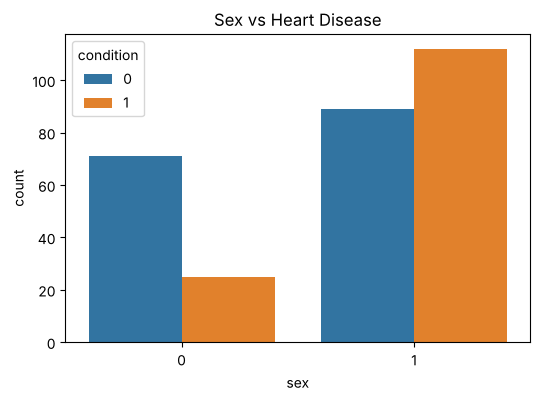

In [37]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='sex', hue='condition')
plt.title('Sex vs Heart Disease')
plt.show()

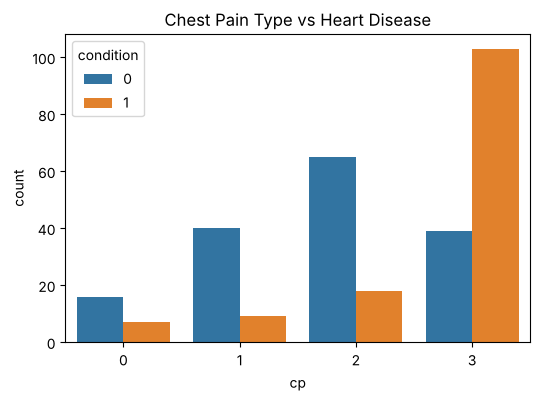

In [38]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='cp', hue='condition')
plt.title('Chest Pain Type vs Heart Disease')
plt.show()

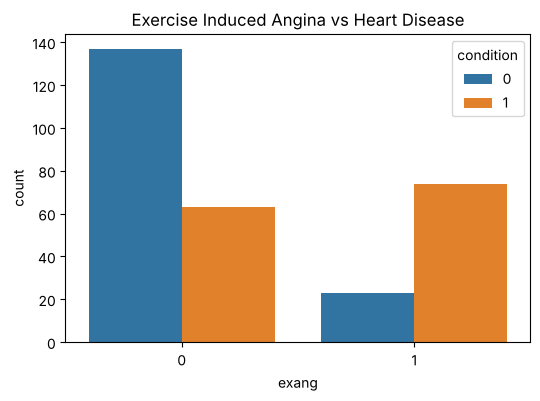

In [39]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='exang', hue='condition')
plt.title('Exercise Induced Angina vs Heart Disease')
plt.show()

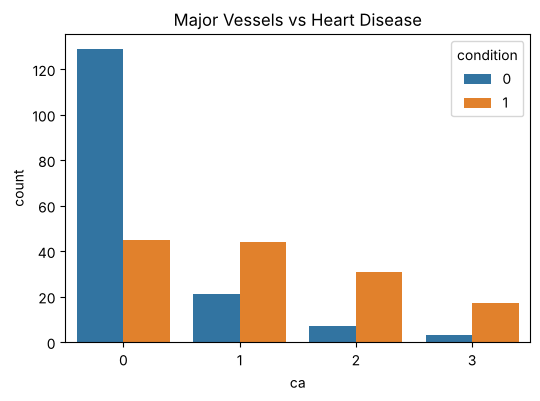

In [40]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='ca', hue='condition')
plt.title('Major Vessels vs Heart Disease')
plt.show()

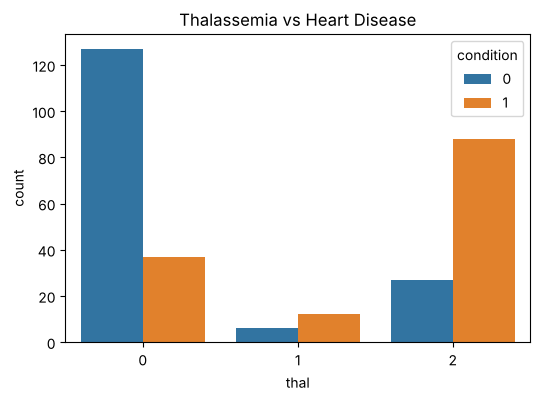

In [41]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='thal', hue='condition')
plt.title('Thalassemia vs Heart Disease')
plt.show()

**Categorical features vs disease:** the share of patients with disease is
- 26% for women vs 56% for men;
- 73% for chest-pain type 3 (vs 18–30% for the other types);
- 76% with exercise-induced angina vs 32% without;
- 26% with no blocked major vessel (`ca = 0`) rising to 82–85% with 2–3 vessels;
- 23% for `thal = 0` vs 67–77% for `thal = 1` or `2`.

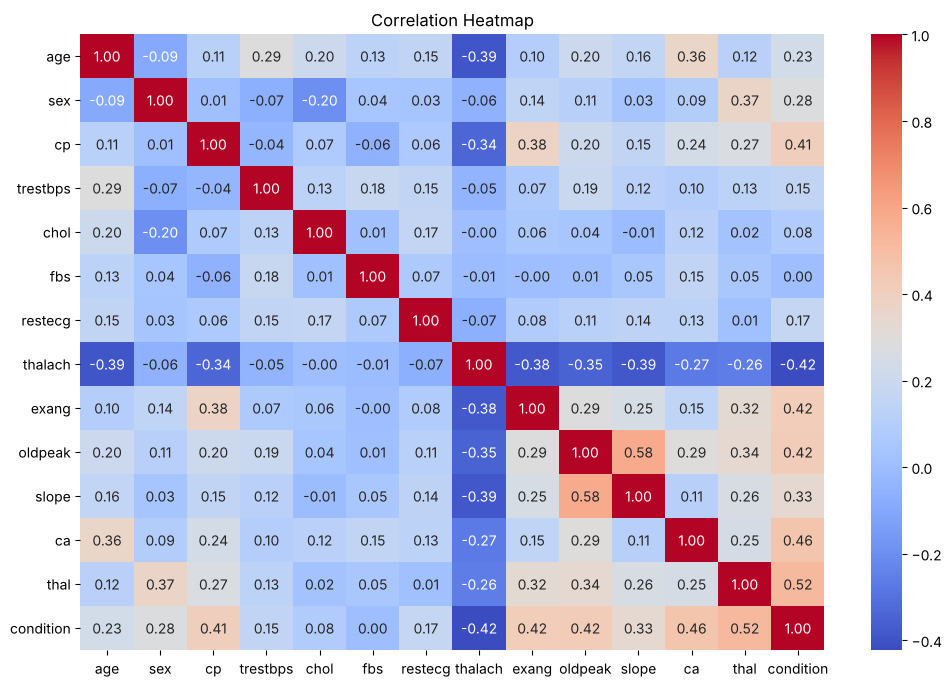

In [42]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

**Correlation heatmap:** the features most associated with disease are `thal` (0.52), `ca` (0.46), `oldpeak`, `exang` and `cp` (≈ 0.42) and, negatively, `thalach` (−0.42). `fbs` has essentially no correlation (0.00). No pair of features is so strongly correlated that it causes a multicollinearity problem.

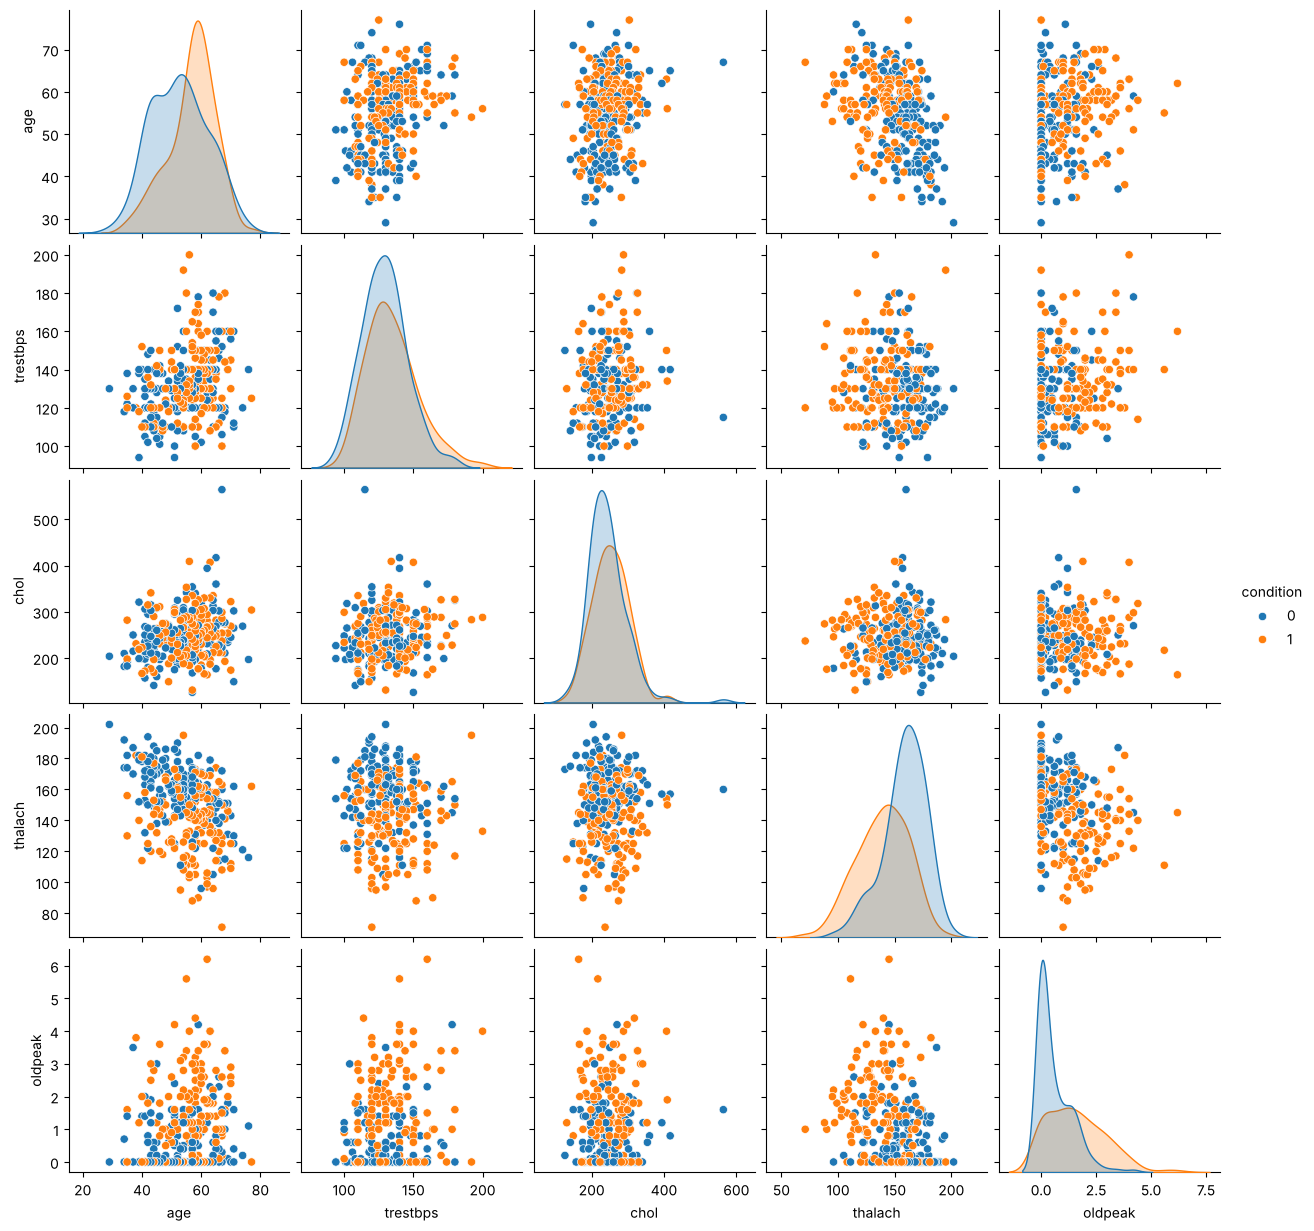

In [43]:
sns.pairplot(
    df[['age','trestbps','chol','thalach','oldpeak','condition']],
    hue='condition'
)

plt.show()

In [44]:
df['condition'].value_counts()

condition
0    160
1    137
Name: count, dtype: int64

In [45]:
df['condition'].value_counts(normalize=True) * 100

condition
0    53.872054
1    46.127946
Name: proportion, dtype: float64

#Train-Test split

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [47]:
print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Labels :", y_train.shape)
print("Testing Labels :", y_test.shape)

Training Features : (237, 13)
Testing Features : (60, 13)
Training Labels : (237,)
Testing Labels : (60,)


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [49]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(237, 13)
(60, 13)


#Model building

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [51]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

In [52]:
results = {}

for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "Support Vector Machine"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:,1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:,1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    }

#Model comparison

In [53]:
results_df = pd.DataFrame(results).T

results_df

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.916667,1.000000,0.821429,0.901961,0.953125
KNN,0.900000,1.000000,0.785714,0.880000,0.959263
Decision Tree,0.783333,0.800000,0.714286,0.754717,0.779018
Random Forest,0.883333,0.956522,0.785714,0.862745,0.940290
Support Vector Machine,0.900000,1.000000,0.785714,0.880000,0.939732


In [54]:
results_df.sort_values(by="Accuracy", ascending=False)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.916667,1.000000,0.821429,0.901961,0.953125
KNN,0.900000,1.000000,0.785714,0.880000,0.959263
Support Vector Machine,0.900000,1.000000,0.785714,0.880000,0.939732
Random Forest,0.883333,0.956522,0.785714,0.862745,0.940290
Decision Tree,0.783333,0.800000,0.714286,0.754717,0.779018


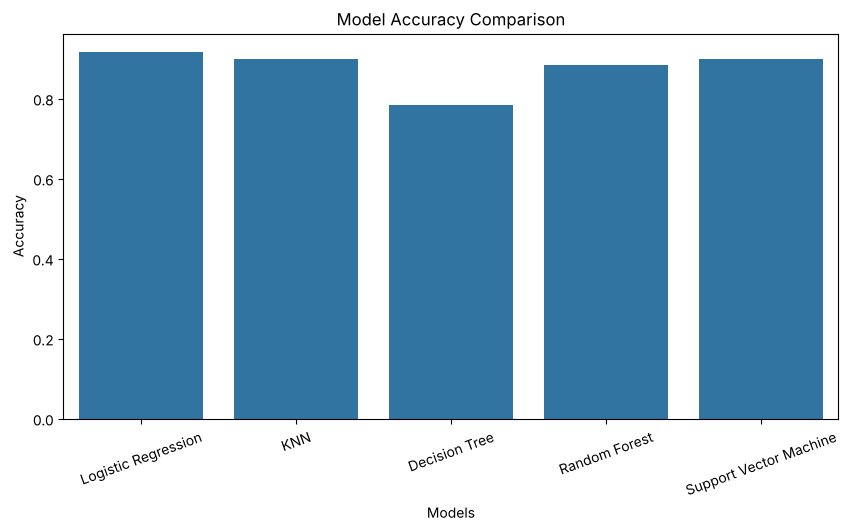

In [55]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=results_df.index,
    y=results_df['Accuracy']
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.show()

In [56]:
results_df.style.background_gradient(cmap='Greens')

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.916667,1.000000,0.821429,0.901961,0.953125
KNN,0.900000,1.000000,0.785714,0.880000,0.959263
Decision Tree,0.783333,0.800000,0.714286,0.754717,0.779018
Random Forest,0.883333,0.956522,0.785714,0.862745,0.940290
Support Vector Machine,0.900000,1.000000,0.785714,0.880000,0.939732


### Cross-validation check

The ranking above comes from a single 60-patient test set, where one patient changes accuracy by about 1.7 percentage points. To check it is not a lucky split, each model is also scored with **5-fold stratified cross-validation on the training set** (scaler refitted inside each fold through a `Pipeline`, so there is no leakage).

In [57]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_rows[name] = {"CV Accuracy": acc.mean(), "CV Accuracy Std": acc.std(), "CV ROC AUC": auc.mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values("CV Accuracy", ascending=False)
cv_df

,CV Accuracy,CV Accuracy Std,CV ROC AUC
Logistic Regression,0.823138,0.053318,0.875869
Support Vector Machine,0.789716,0.068241,0.872075
KNN,0.768528,0.060074,0.850817
Random Forest,0.768174,0.043080,0.871150
Decision Tree,0.734663,0.058314,0.729750


**Result:** Logistic Regression is also the best model under cross-validation (≈ 82% accuracy), so its lead is not just a lucky split. Note that every model scores about 5–13 points lower in cross-validation than on the hold-out test set — the test split happens to be an easy one, and **cross-validated accuracy is the more realistic estimate**.

#Best model

In [58]:
best_model_name = results_df["Accuracy"].idxmax()

print("Best Model:", best_model_name)

best_model = models[best_model_name]

Best Model: Logistic Regression


In [59]:
if best_model_name in ["Logistic Regression", "KNN", "Support Vector Machine"]:
    y_pred = best_model.predict(X_test_scaled)
    y_prob = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

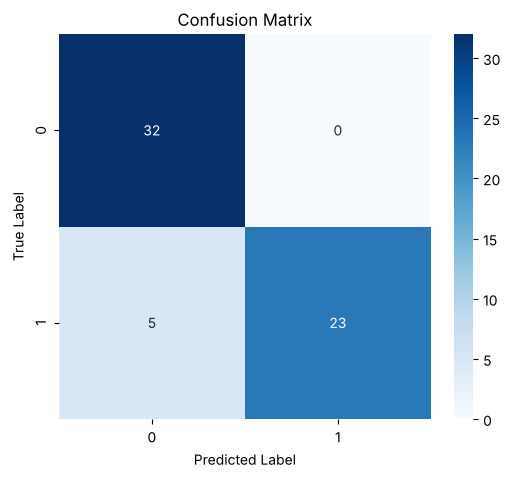

In [60]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

In [61]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      1.00      0.93        32
           1       1.00      0.82      0.90        28

    accuracy                           0.92        60
   macro avg       0.93      0.91      0.91        60
weighted avg       0.93      0.92      0.92        60



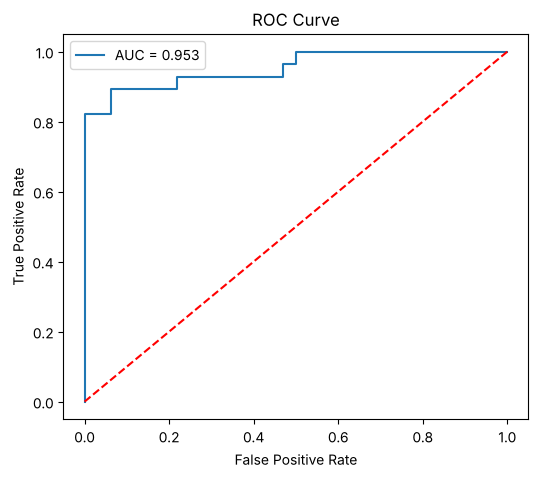

In [62]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")

plt.plot([0,1],[0,1],'r--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

#Hyperparameter Tuning

In [63]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",T

In [64]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}

Best Cross Validation Score:
0.8233156028368794


In [65]:
best_rf = grid_search.best_estimator_

In [66]:
from sklearn.metrics import accuracy_score

y_pred = best_rf.predict(X_test)

print("Test Accuracy:")
print(accuracy_score(y_test, y_pred))

Test Accuracy:
0.85


### Tuning Logistic Regression as well

Logistic Regression was the best model in the comparison, so it is tuned too and compared fairly with the tuned Random Forest. The search maximises **ROC-AUC** (threshold-free and less noisy on small data), and the final model is chosen by **cross-validated ROC-AUC on the training set only** — never by looking at the test set.

In [67]:
lr_pipe = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(solver="liblinear", random_state=42))])

lr_grid = GridSearchCV(
    lr_pipe,
    param_grid={"model__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 100], "model__penalty": ["l1", "l2"]},
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:", lr_grid.best_params_)
print("Best CV ROC AUC:", round(lr_grid.best_score_, 4))

Best Logistic Regression parameters: {'model__C': 0.1, 'model__penalty': 'l1'}
Best CV ROC AUC: 0.8963


In [68]:
best_lr = lr_grid.best_estimator_

candidates = {
    "Logistic Regression (default)": Pipeline([("scaler", StandardScaler()),
                                               ("model", LogisticRegression(max_iter=1000, random_state=42))]),
    "Logistic Regression (tuned)": best_lr,
    "Random Forest (tuned)": best_rf,
}

final_rows = {}
for name, est in candidates.items():
    est.fit(X_train, y_train)
    final_rows[name] = {
        "CV ROC AUC": cross_val_score(est, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
        "CV Accuracy": cross_val_score(est, X_train, y_train, cv=cv, scoring="accuracy").mean(),
        "Test Accuracy": accuracy_score(y_test, est.predict(X_test)),
        "Test Recall": recall_score(y_test, est.predict(X_test)),
        "Test ROC AUC": roc_auc_score(y_test, est.predict_proba(X_test)[:, 1]),
    }

final_df = pd.DataFrame(final_rows).T
final_name = final_df["CV ROC AUC"].idxmax()
final_model = candidates[final_name]

display(final_df.round(3))
print("Final model (highest CV ROC AUC):", final_name)

Final model (highest CV ROC AUC): Logistic Regression (tuned)


,CV ROC AUC,CV Accuracy,Test Accuracy,Test Recall,Test ROC AUC
Logistic Regression (default),0.876,0.823,0.917,0.821,0.953
Logistic Regression (tuned),0.896,0.823,0.900,0.786,0.912
Random Forest (tuned),0.884,0.798,0.850,0.714,0.944


**Why this selection rule:** picking the final model by the highest score on a 60-patient test set would be unreliable and would leak test information into the choice. Cross-validated ROC-AUC uses all 237 training patients and keeps the test set untouched for an honest final report.

#Feature Importance

In [69]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
2,cp,0.152347
7,thalach,0.140957
11,ca,0.136344
9,oldpeak,0.128538
12,thal,0.120784
0,age,0.078871
8,exang,0.068362
4,chol,0.051386
3,trestbps,0.047802
10,slope,0.038037


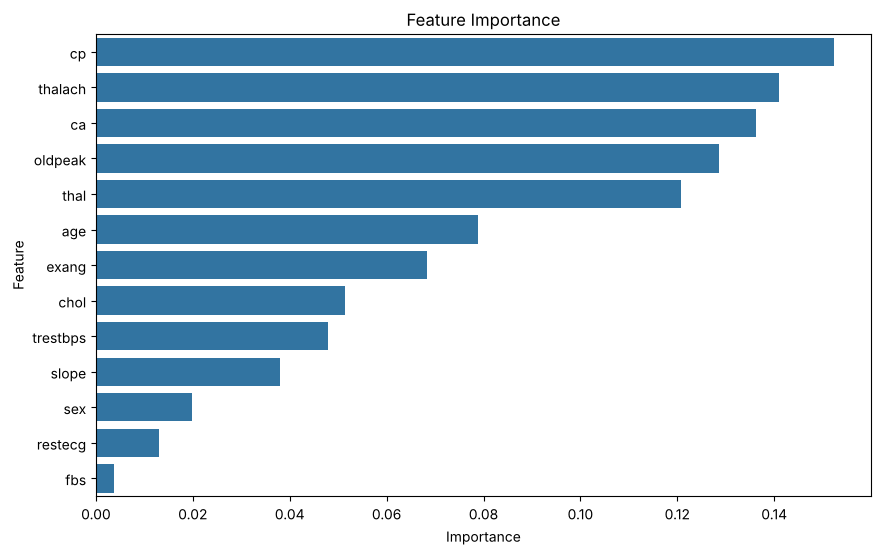

In [70]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance")
plt.show()

In [71]:
y_pred_final = final_model.predict(X_test)
y_prob_final = final_model.predict_proba(X_test)[:, 1]

print("Final model:", final_name)
print(classification_report(y_test, y_pred_final, target_names=["No disease", "Disease"]))
print("Test ROC AUC:", round(roc_auc_score(y_test, y_prob_final), 3))

Final model: Logistic Regression (tuned)
              precision    recall  f1-score   support

  No disease       0.84      1.00      0.91        32
     Disease       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60

Test ROC AUC: 0.912


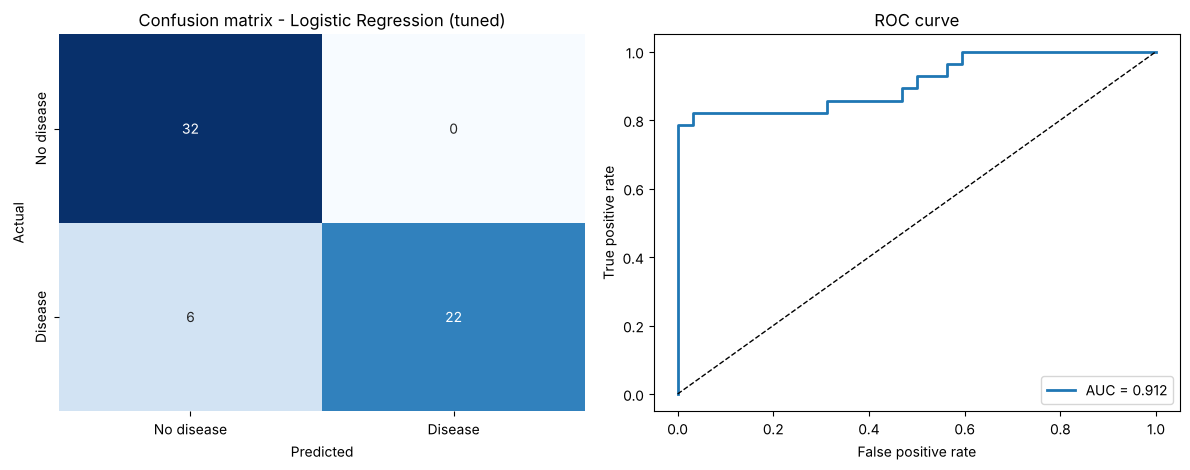

In [72]:
import os
os.makedirs("../images", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

cm_final = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
axes[0].set_title(f"Confusion matrix - {final_name}")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

fpr_f, tpr_f, _ = roc_curve(y_test, y_prob_final)
axes[1].plot(fpr_f, tpr_f, lw=2, label=f"AUC = {roc_auc_score(y_test, y_prob_final):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("../images/confusion_matrix_roc.png", dpi=130, bbox_inches="tight")
plt.show()

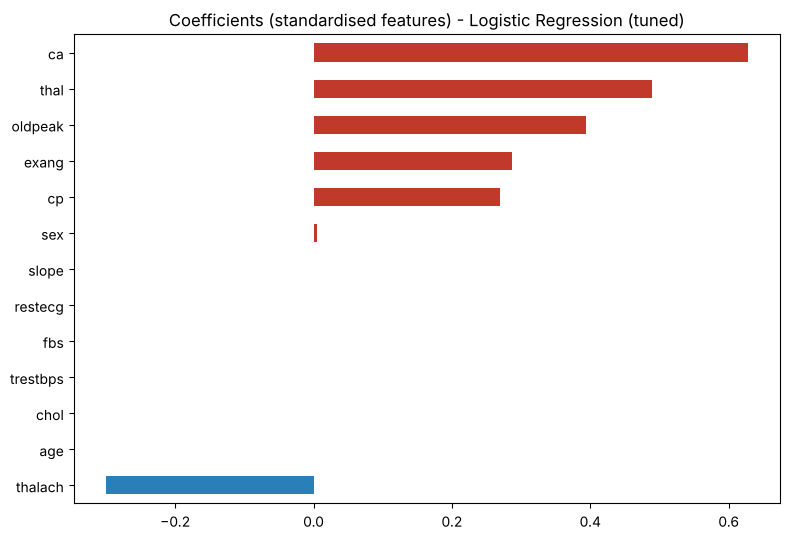

ca          0.628
thal        0.490
oldpeak     0.393
exang       0.287
cp          0.269
sex         0.005
age         0.000
chol        0.000
trestbps    0.000
restecg     0.000
fbs         0.000
slope       0.000
thalach    -0.300
dtype: float64

In [73]:
if hasattr(final_model.named_steps["model"], "coef_"):
    coef = pd.Series(final_model.named_steps["model"].coef_[0], index=X.columns).sort_values()
    title = f"Coefficients (standardised features) - {final_name}"
else:
    coef = pd.Series(final_model.feature_importances_, index=X.columns).sort_values()
    title = f"Feature importance - {final_name}"

plt.figure(figsize=(8, 5.5))
coef.plot(kind="barh", color=["#c0392b" if v > 0 else "#2980b9" for v in coef])
plt.title(title)
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=130, bbox_inches="tight")
plt.show()
coef.sort_values(ascending=False).round(3)

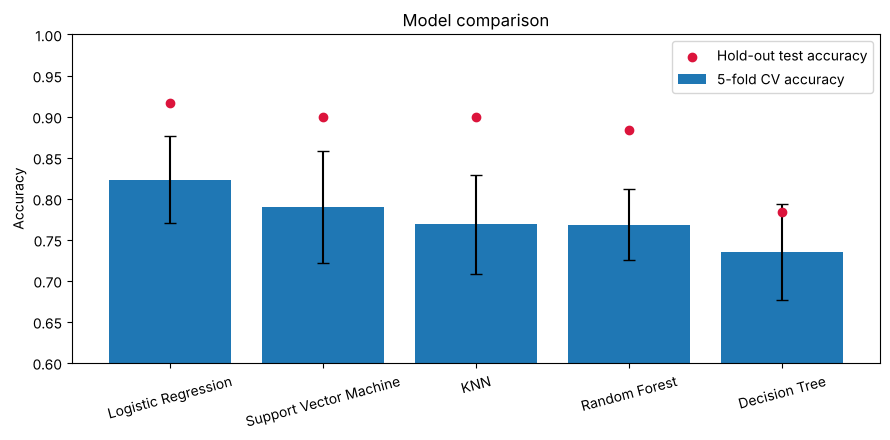

In [74]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cmp = cv_df.copy()
cmp["Test Accuracy"] = results_df.loc[cmp.index, "Accuracy"]
ax.bar(cmp.index, cmp["CV Accuracy"], yerr=cmp["CV Accuracy Std"], capsize=4, label="5-fold CV accuracy")
ax.scatter(cmp.index, cmp["Test Accuracy"], color="crimson", zorder=3, label="Hold-out test accuracy")
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Accuracy"); ax.set_title("Model comparison")
ax.legend(loc="upper right")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

**Interpretation:** the coefficients/importances above show which clinical measurements drive the prediction. Positive bars push towards heart disease, negative bars (e.g. `thalach`) towards a healthy result. The confusion matrix shows how many sick patients are still missed (false negatives) — the error that matters most in a medical setting.

#Saving the model

In [75]:
import joblib

joblib.dump(final_model, '../models/heart_disease_model.pkl')  # final_model is a Pipeline (scaler + model): it accepts raw patient values

print("Model Saved Successfully!")

Model Saved Successfully!


#Conclusion

In this project, a Heart Disease Prediction system was developed using multiple machine learning algorithms. After preprocessing the data and performing exploratory data analysis, five classification models were trained and evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC, both on a hold-out test set and with 5-fold cross-validation.

**Findings**
- Logistic Regression was the best model on both the hold-out split (91.7% accuracy) and in cross-validation (82.3% accuracy, 0.876 ROC-AUC). Cross-validated accuracy (about 82%) is the more realistic estimate; the 60-patient test split turned out to be an easy one.
- Logistic Regression and Random Forest were both tuned with GridSearchCV. The final model was chosen by cross-validated ROC-AUC on the training set only: **tuned Logistic Regression (L1 penalty, C = 0.1; CV ROC-AUC 0.896)**.
- On the untouched test set the final model reaches 90% accuracy, 100% precision, 79% recall and 0.912 ROC-AUC. It still misses about one in five patients with heart disease, which matters in a medical setting.
- The most influential features are the number of blocked major vessels (ca), thalassemia result (thal), ST depression (oldpeak), exercise-induced angina (exang), chest-pain type (cp) and, protectively, maximum heart rate (thalach). The L1 penalty removed cholesterol, resting blood pressure, fasting blood sugar and other weak features.

**Limitations and next steps:** only 297 patients from one clinic and a 60-patient test set mean small differences between models are within noise. Next steps are repeated or nested cross-validation, tuning the decision threshold for higher recall, and a simple web app. This is an educational project, not a medical device.